In [1]:
# Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the target column
df["species"] = iris.target

# Display the first five rows
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Get information about the dataset
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check the distribution of flower species
print("\nSpecies distribution:")
print(df["species"].value_counts().sort_index())

Dataset shape: (150, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species distribution:
species
0    50
1    50
2    50
Name: count, dtype: int64


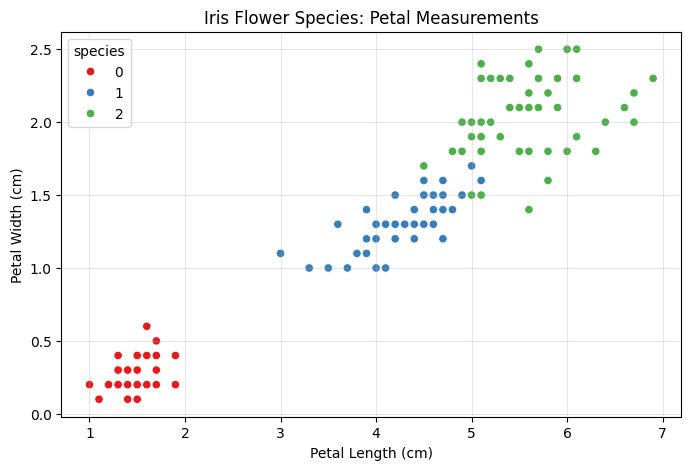

In [3]:
# Visualize petal length against petal width
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    palette="Set1"
)

plt.title("Iris Flower Species: Petal Measurements")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.grid(alpha=0.3)
plt.show()

In [4]:
# Select the input features
X = df[iris.feature_names]

# Select the target labels
y = iris.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five feature rows:")
display(X.head())

print("\nFirst five target labels:")
print(y[:5])

Features shape: (150, 4)
Target shape: (150,)

First five feature rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



First five target labels:
[0 0 0 0 0]


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [6]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [7]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Make predictions on unseen test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model accuracy: {accuracy:.2%}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Model accuracy: 96.67%

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



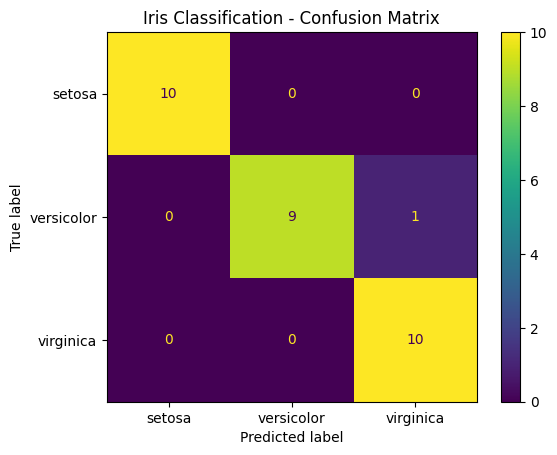

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display it
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display.plot()
plt.title("Iris Classification - Confusion Matrix")
plt.show()

In [9]:
# Example flower measurements:
# sepal length, sepal width, petal length, petal width

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

# Predict the species
prediction = model.predict(new_flower)

predicted_species = iris.target_names[prediction[0]]

print("Predicted flower species:", predicted_species)

Predicted flower species: setosa


In [10]:
import os
import joblib

# Create the models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the trained model
joblib.dump(model, "../models/iris_decision_tree.pkl")

print("Model saved successfully!")


Model saved successfully!


In [11]:
import joblib

print("Joblib is ready!")

Joblib is ready!
